## Mode and Distance Travel Efficiency (Flag 24)

### Dataset Overview
An independently constructed, road-aligned WorldTrace case containing 172 trajectories.

The notebook exposes a primary table and a supporting table (`trajectory_points.csv`).

Goal: Analyze variations in travel efficiency across travel modes and trip distances.

Role: Mobility-pattern analyst


Category: Travel mode, distance, travel time, and short-trip exceptions

### Your Objective
Use the provided tables and visual evidence to answer the questions below and summarize the observed trajectory patterns.


## Import Necessary Libraries

This cell loads the data-analysis and visualization libraries used by the questions below.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, SVG, display

## Load Dataset

The primary table is loaded into `df`; when available, the supporting trajectory or driver table is loaded into `user_df`.

In [ ]:
dataset_path = "trajectories.csv"
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv(dataset_path)

In [ ]:
user_dataset_path = "trajectory_points.csv"
user_df = pd.read_csv(user_dataset_path)

### **Question 1**: How does travel time compare between car and cycling trips over similar distances?

#### Analysis action

Compare mode-specific travel-time distributions within matched distance bands.

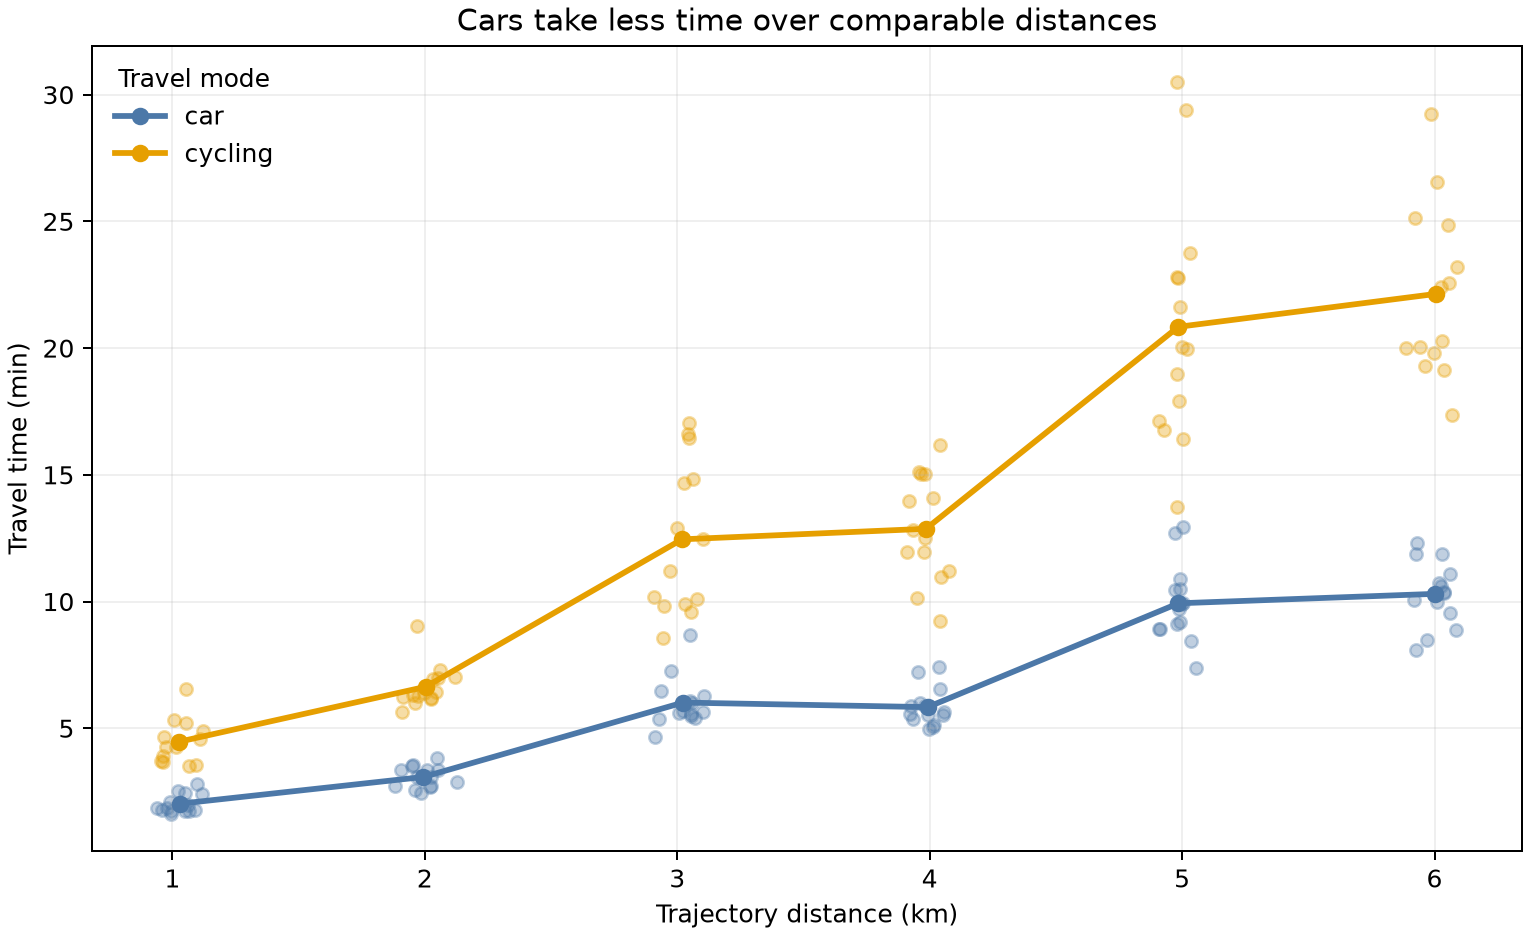

In [ ]:
print(df.groupby(['distance_band_km','travel_mode']).travel_time_min.mean().unstack())
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/insight_1.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "worldtrace_ex24_insight_1",
  "insight": "Car trips generally take less time than cycling trips over similar travel distances.",
  "plot": {
    "plot_type": "question_specific_summary",
    "title": "Mode and Distance Travel Efficiency: Insight 1",
    "description": "Question-specific evidence computed from the synchronized trajectory and point tables; the case-level route overview is retained separately.",
    "file": "visualizations/insight_1.png"
  },
  "question": "How does travel time compare between car and cycling trips over similar distances?",
  "actionable_insight": "Compare mode-specific travel-time distributions within matched distance bands.",
  "code": "print(df.groupby(['distance_band_km','travel_mode']).travel_time_min.mean().unstack())",
  "insight_type": "group_comparison",
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "transport_mode",
    "gps_position",
    "trajectory_timestamp",
    "trajectory_id"
  ]
}

### **Question 2**: Does the cycling–car travel-time gap change with distance, and do the modes have similar route-directness patterns?

#### Analysis action

Compare the cycling-minus-car time gap and mode-specific route-directness ratios across distance bands.

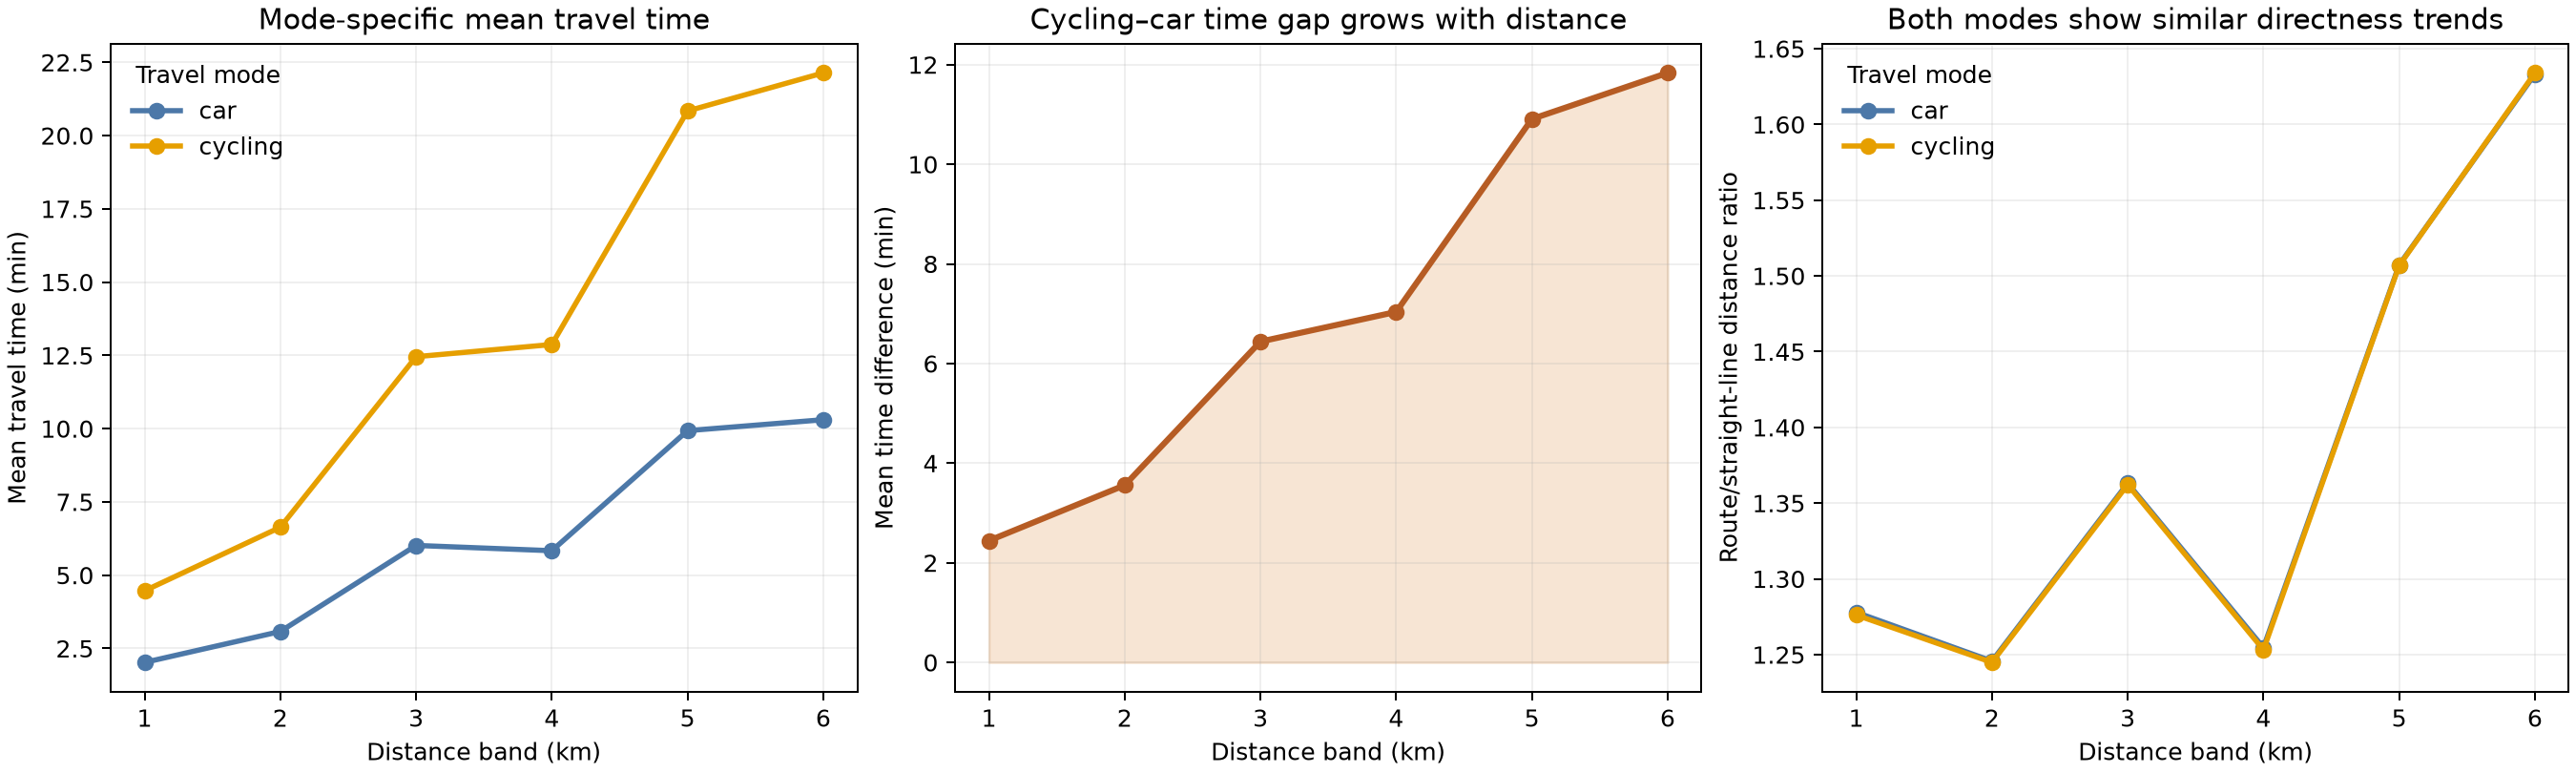

In [ ]:
q=df[~df.is_fast_cycling_exception]; m=q.groupby(['distance_band_km','travel_mode']).travel_time_min.mean().unstack(); r=q.groupby(['distance_band_km','travel_mode']).route_directness_ratio.mean().unstack(); print(m.cycling-m.car); print(r)
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/insight_2.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "worldtrace_ex24_insight_2",
  "insight": "The travel-time difference between cycling and car trips increases with trip distance, but their overall route-directness ratios are similar and follow the same tendency as trip distance increases.",
  "plot": {
    "plot_type": "question_specific_summary",
    "title": "Mode and Distance Travel Efficiency: Insight 2",
    "description": "Question-specific evidence computed from the synchronized trajectory and point tables; the case-level route overview is retained separately.",
    "file": "visualizations/insight_2.png"
  },
  "question": "Does the cycling–car travel-time gap change with distance, and do the modes have similar route-directness patterns?",
  "actionable_insight": "Compare the cycling-minus-car time gap and mode-specific route-directness ratios across distance bands.",
  "code": "q=df[~df.is_fast_cycling_exception]; m=q.groupby(['distance_band_km','travel_mode']).travel_time_min.mean().unstack(); r=q.groupby(['distance_band_km','travel_mode']).route_directness_ratio.mean().unstack(); print(m.cycling-m.car); print(r)",
  "insight_type": "factor_relationship",
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "transport_mode",
    "gps_position",
    "trajectory_timestamp",
    "trajectory_id"
  ]
}

### **Question 3**: Are there short cycling trips whose travel times are comparable to car trips?

#### Analysis action

Inspect short-trip cycling exceptions against the regular short car distribution.

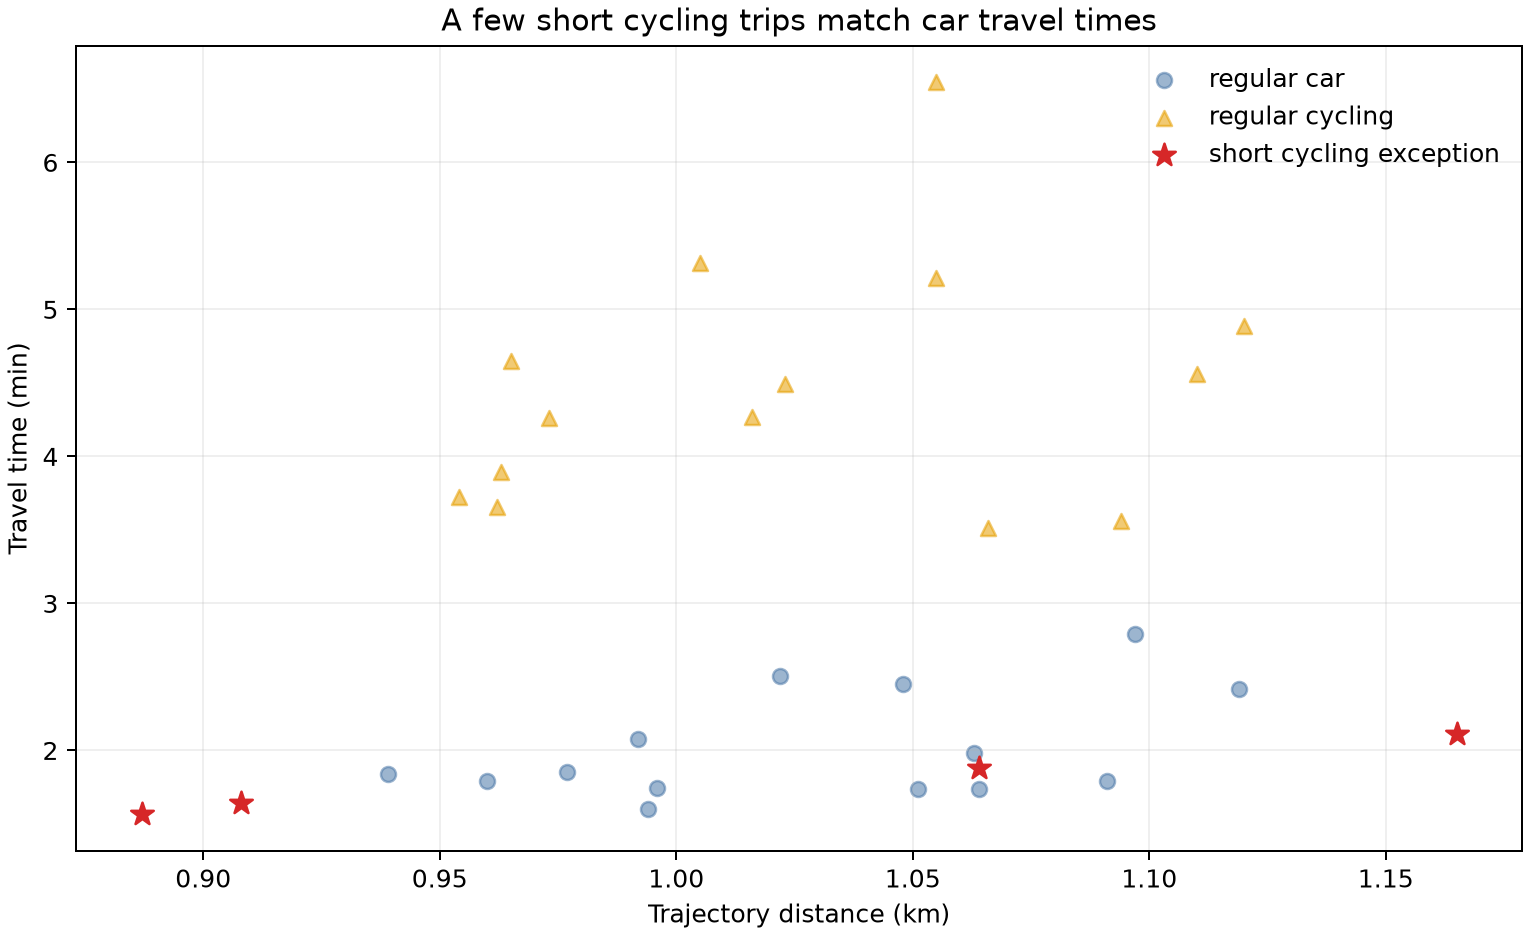

In [ ]:
print(df[df.trajectory_distance_km.le(1.3)].groupby(['travel_mode','is_fast_cycling_exception']).travel_time_min.describe())
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/insight_3.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "worldtrace_ex24_insight_3",
  "insight": "A few short cycling trips have travel times comparable to similar car trips.",
  "plot": {
    "plot_type": "question_specific_summary",
    "title": "Mode and Distance Travel Efficiency: Insight 3",
    "description": "Question-specific evidence computed from the synchronized trajectory and point tables; the case-level route overview is retained separately.",
    "file": "visualizations/insight_3.png"
  },
  "question": "Are there short cycling trips whose travel times are comparable to car trips?",
  "actionable_insight": "Inspect short-trip cycling exceptions against the regular short car distribution.",
  "code": "print(df[df.trajectory_distance_km.le(1.3)].groupby(['travel_mode','is_fast_cycling_exception']).travel_time_min.describe())",
  "insight_type": "exception_deviation",
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "transport_mode",
    "gps_position",
    "trajectory_timestamp",
    "trajectory_id"
  ]
}

### Summary of Findings (Flag 24)

Car trips generally take less time than cycling trips over similar travel distances. The travel-time difference between cycling and car trips increases with trip distance, but their overall route-directness ratios are similar and follow the same tendency as trip distance increases. A few short cycling trips have travel times comparable to similar car trips.